# How the voltage-reference controller works
**Adnane Essoufi. Solo project. Apache-2.0. Optional circuit details.**

The main lesson compares three reset circuits. This notebook explains the third
choice: a self-biased voltage reference and transistor comparator. It meets all
seven sampled requirements, at a higher cost during ordinary storage.

The four code cells check **saved Windows simulations**. They rebuild the circuit
decks and repeat the measurements. They run no new SPICE simulations.
All three controllers use the same flip-flop, load, normal write and matched
supplies. The circuits use established ideas.

In [1]:
from pathlib import Path
import hashlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from reference_evidence import audit, policy_evidence

HERE = Path.cwd()
audit_path = HERE / "results/reference/evidence_manifest.json"
saved = audit()  # Saved vectors and regenerated decks; no fresh SPICE.
study = dict(status="audited",
    primary=[r for r in saved["cases"] if r["id"].startswith("primary/")],
    followup=[r for r in saved["cases"] if r["id"].startswith("followup/")],
    reference_loops=[r for r in saved["cases"] if r["kind"] == "loop"])
print("Saved evidence manifest SHA256:", hashlib.sha256(audit_path.read_bytes()).hexdigest())
print("Primary intact acquisitions:", len(study["primary"]))
print("Follow-up acquisitions:", len(study["followup"]))

PASS: all 56 saved reference acquisitions regenerated and remeasured.


Saved evidence manifest SHA256: 8ec5900798445b642b0a6e454bd96051595599564630647e1fa642b331b3ada9
Primary intact acquisitions: 21
Follow-up acquisitions: 17


## Check startup and the write before judging reset

The table separates a startup failure from a reset miss after Q=1 was written.
A storage test instead requires Q=1 and inactive reset throughout the post-write
interval. The seven conditions use typical transistor models (TT), at -40, 27
or 125 C. They do not qualify a continuous temperature range.

| History | Original POR | POR + guard | Reference |
|---|---|---|---|
| cold_storage | Cold setup not established | Cold setup not established | Meets requirement |
| cold_shallow | Cold setup not established | Cold setup not established | Meets requirement |
| nominal_storage | Meets requirement | Meets requirement | Meets requirement |
| nominal_shallow | Exercised reset miss | Meets requirement | Meets requirement |
| hot_storage | Meets requirement | Meets requirement | Meets requirement |
| hot_shallow | Exercised reset miss | Exercised reset miss | Meets requirement |
| nominal_analog | Meets requirement | Meets requirement | Meets requirement |

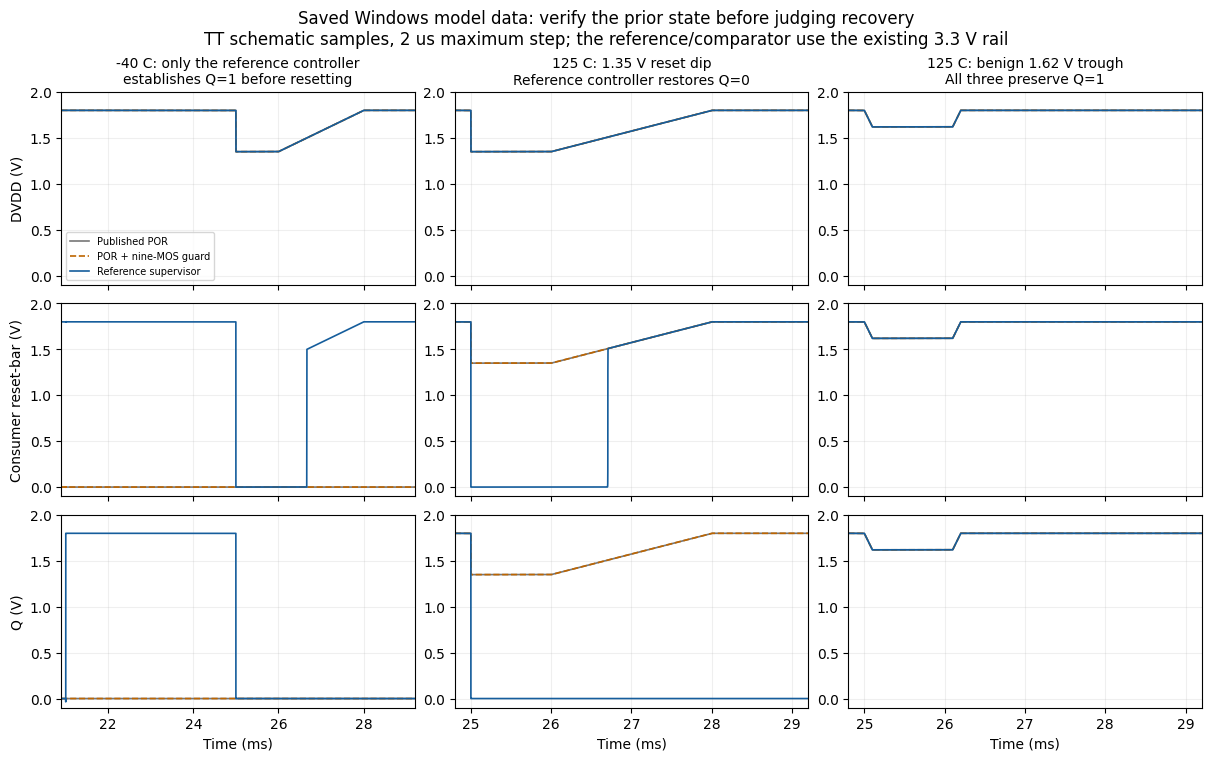

In [2]:
variants = ["original", "digital_guard", "reference_supervisor"]
cases = ["cold_storage", "cold_shallow", "nominal_storage", "nominal_shallow",
         "hot_storage", "hot_shallow", "nominal_analog"]
index = {(r["case"], r["variant"]): r for r in study["primary"]}
labels = {"requirement_met": "Meets requirement",
          "not_exercised_cold_start": "Cold setup not established",
          "not_exercised_prior_state": "Prior state not established",
          "functional_requirement_missed": "Exercised reset miss"}
table = ["| History | Original POR | POR + guard | Reference |",
         "|---|---|---|---|"]
for case in cases:
    table.append("| " + case + " | " + " | ".join(
        labels[index[(case, v)]["result"]["diagnosis"]] for v in variants) + " |")
display(Markdown("\n".join(table)))
from reference_figures import show
display(show(saved))
plt.close("all")

## Why the reference helps

The guard depends on a MOS switching level. The other controller compares DVDD
with a voltage reference. It combines $V_{BE}$ and $\Delta V_{BE}$, whose
temperature trends oppose each other.

The 220 kohm / 1 Mohm divider suggests $V_{DD}\approx1.22V_{ref}$, about 1.50 V
for the three settled references. This is a design estimate. The complete
circuit traces, not this estimate, tell us whether reset works.

The reference needs its own startup circuit. Without it, all three sampled
starts miss the readiness test. With it, they pass, but overshoot reaches
1.633 V. The output is not regulated precisely during startup.
[REFERENCE.md](REFERENCE.md) credits the reused amplifier and startup blocks.

In [3]:
rows = [r for r in study["reference_loops"] if r["startup"]]
table = ["| TT temperature, C | Measured final reference, V | Divider estimate, V |",
         "|---:|---:|---:|"]
for r in rows:
    ref = r["result"]["final_reference_V"]
    table.append(f"| {r['temp_C']} | {ref:.6f} | {1.22*ref:.6f} |")
display(Markdown("\n".join(table)))
print("Three sampled reference-only settled values; not intact measured switching thresholds.")

| TT temperature, C | Measured final reference, V | Divider estimate, V |
|---:|---:|---:|
| -40 | 1.228930 | 1.499295 |
| 27 | 1.233210 | 1.504516 |
| 125 | 1.236874 | 1.508986 |

Three sampled reference-only settled values; not intact measured switching thresholds.


## Compare energy only when the circuit works

Both rows below use smaller-step matched runs and count startup plus all four
sources. The reference uses about 40.31% more supplied energy for 27 C storage
and 19.80% less for the separate analog interruption. Its primary 125 C storage
cost is about 157.59% higher. These are separate tests, not lifetime energy use.

Edit `required_histories`. The selector first checks that every requirement is
met. It then compares the remaining choices at the same storage test.
Missing evidence returns `None`. A failed circuit cannot win by drawing less.

In [4]:
from guard_policy import choose

refined = {(r["case"], r["variant"]): r for r in study["followup"] if r["group"] == "step"}
table = ["| Refined history | Original, uJ | Guard, uJ | Reference, uJ |",
         "|---|---:|---:|---:|"]
for case in ["nominal_storage", "nominal_analog"]:
    members = [refined[(case, v)] for v in variants]
    assert all(r["result"]["qualified"] for r in members)
    assert all(r["source_functions"] == members[0]["source_functions"] for r in members)
    table.append("| " + case + " | " + " | ".join(
        f"{r['result']['reference']['source_work']['delivered_J']*1e6:.6f}"
        for r in members) + " |")
display(Markdown("\n".join(table)))

evidence = policy_evidence(saved)
required_histories = ["nominal_storage", "nominal_shallow"]
print("Your requirements =>", choose(evidence, required=required_histories, anchor="nominal_storage"))
for required in [["nominal_storage"], ["nominal_storage", "nominal_shallow"], cases,
                 ["nominal_storage", "unmeasured_short_zero"]]:
    print(required, "=>", choose(evidence, required=required, anchor="nominal_storage"))

| Refined history | Original, uJ | Guard, uJ | Reference, uJ |
|---|---:|---:|---:|
| nominal_storage | 0.894466 | 0.906937 | 1.255022 |
| nominal_analog | 1.480795 | 1.493371 | 1.187545 |

Your requirements => digital_guard
['nominal_storage'] => original
['nominal_storage', 'nominal_shallow'] => digital_guard
['cold_storage', 'cold_shallow', 'nominal_storage', 'nominal_shallow', 'hot_storage', 'hot_shallow', 'nominal_analog'] => reference_supervisor
['nominal_storage', 'unmeasured_short_zero'] => None


The reference meets the broader sampled requirements, with its cost shown.
Added passives are ideal. The reused analog blocks and logic keep their
documented geometry. Hardware retention, noise and full process/voltage/
temperature coverage are unverified.

After setup, `python reproduce_reference.py` runs ten selected new simulations.
[REFERENCE.md](REFERENCE.md) gives the individual-case commands and exact limits.